# Datasets

Snapshot datasets (one feature vector per fault event) are bundled. Event trajectories come from PowerFactory exports or from a simulation engine.

In [1]:
import numpy as np
import tranpy
from pathlib import Path
import matplotlib.pyplot as plt
from tranpy_core.plotting import publication_style, save_figure

FIGURES = Path("outputs")
plt.rcParams["figure.dpi"] = 150

## What is available

In [2]:
tranpy.list_datasets()

,system,kind,n_samples,bundled,download_url,filename
0,new_england,snapshots,5000,True,None,new_england_snapshots.npz
1,ieee_9bus,snapshots,5000,True,None,ieee_9bus_snapshots.npz
2,new_england,events,500,False,None,new_england_events.npz
3,ieee_9bus,events,500,False,None,ieee_9bus_events.npz


## Snapshot datasets

In [3]:
for load in (tranpy.load_new_england, tranpy.load_ieee_9bus):
    ds = load()
    print(ds, "| duplicated rows:", ds.n_samples - len(np.unique(ds.features, axis=0)))

TabularDataset('new_england', samples=5000, features=77, stable=2650, unstable=2350) | duplicated rows: 25
TabularDataset('ieee_9bus', samples=5000, features=17, stable=3599, unstable=1401) | duplicated rows: 22


In [4]:
ds = tranpy.load_ieee_9bus()
ds.to_frame().describe().T.head(8).round(3)

,count,mean,std,min,25%,50%,75%,max
Bus 1 voltage (p.u.),5000.0,0.800,0.077,0.669,0.699,0.838,0.862,0.903
Bus 2 voltage (p.u.),5000.0,0.587,0.117,0.355,0.511,0.612,0.698,0.767
Bus 3 voltage (p.u.),5000.0,0.521,0.114,0.309,0.437,0.509,0.636,0.694
Bus 4 voltage (p.u.),5000.0,0.534,0.154,0.298,0.330,0.612,0.662,0.707
Bus 5 voltage (p.u.),5000.0,0.399,0.160,0.097,0.289,0.451,0.545,0.619
Bus 6 voltage (p.u.),5000.0,0.395,0.163,0.096,0.295,0.399,0.546,0.601
Bus 7 voltage (p.u.),5000.0,0.434,0.156,0.151,0.334,0.485,0.588,0.649
Bus 8 voltage (p.u.),5000.0,0.371,0.178,0.093,0.162,0.450,0.527,0.591


## Event trajectories

Recorded events load from a folder of PowerFactory result CSVs or a converted file:

```python
events = tranpy.load_events("new_england", source="path/to/csv_folder")
```

Here the mock engine provides comparable data without PowerFactory.

In [5]:
from tranpy.simulation import MockEngine, ScenarioSampler, generate_events

engine = MockEngine("ieee_9bus", simulation_time_s=5.0)
sampler = ScenarioSampler(n_lines=engine.n_lines, n_loads=engine.n_loads, simulation_time_s=5.0,
                          clearing_cycles=20, operating_point=(0.6, 1.4))
events = generate_events(engine, sampler.sample(120, seed=0)).drop_channels("*|s:outofstep")
events

SignalDataset('ieee_9bus_simulated', samples=120, channels=42, rows=61320, stable=71, unstable=49)

In [6]:
sample = events[0]
sample.time.shape, sample.values.shape, dict(sample.annotations)

((511,),
 (511, 42),
 {'fault_start_s': 1.0113795995538206,
  'fault_clear_s': 1.4113795995538205,
  'fault_line': 2.0,
  'load_index': 1.0,
  'load_change_pct': 0.0,
  'fault_resistance_ohm': 0.01,
  'fault_reactance_ohm': 0.01,
  'trip_line': nan,
  'operating_point': 1.2947449235337836})

In [7]:
events.channel_names[:6]

('Bus 01|m:u in p.u.',
 'Bus 01|m:phiu in deg',
 'Bus 01|m:fehz in Hz',
 'Bus 02|m:u in p.u.',
 'Bus 02|m:phiu in deg',
 'Bus 02|m:fehz in Hz')

## Rotor angles of stable and unstable events

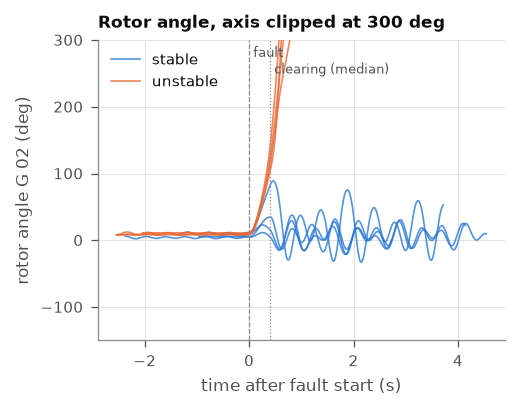

In [8]:
from tranpy.plotting import plot_trajectories

with publication_style():
    fig = plot_trajectories(events, "G 02|c:firot in deg", per_class=4, seed=1,
                            ylabel="rotor angle G 02 (deg)", title="Rotor angle, axis clipped at 300 deg")
    fig.axes[0].set_ylim(-150, 300)
    save_figure(fig, FIGURES / "02_rotor_angle.pdf")
plt.show()